# Fig. 2 · L0 数值参考一致性（H5 审计集，120 帧 × 306 原子）

**主张**：L0 只问"给定构型上 E/F/S 算得准不准"，误差按元素、力幅、状态点分箱后，才能看出误差住在哪里。

- **a, b** 力分量 parity：MACE-MPA-0（通用）与 MACE-spec-GST（同架构，只换训练数据）。
- **c** 力矢量 MAE 随参考力幅 |F| 的变化（四个代表模型）。
- **d** 力 MAE；**e** 分元素力 MAE；**f** 能量 MAE（扣除同组成常数偏移后）。d–f 共用 y 轴（9 个模型）。

审计集角色为 `protected_audit`：只打分，不导出补算候选。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig2_L0"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 2
LETTERS = "abcdef"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
def model_rows(ax, show_labels):
    """Shared y axis for the nine-model summary panels: universal on top, specialised below."""
    y = {k: i for i, k in enumerate(SHOWCASE)}
    ax.set_ylim(len(SHOWCASE) - 0.4, -0.6)
    ax.set_yticks(range(len(SHOWCASE)))
    ax.set_yticklabels([lab(k) for k in SHOWCASE] if show_labels else [])
    ax.axhline(len(UNIVERSAL) - 0.5, color="#BBBBBB", lw=0.4, ls=(0, (2, 2)))
    ax.tick_params(axis="y", length=0)
    return y

def contaminated(model):
    from mlipeval.ranking import contaminated_metric_ids
    return set(contaminated_metric_ids([model]))

In [5]:
from ase.io import read
from mlipeval import crossmodel as cm
FRAMES = read(str(EVAL_HOME / "data/reference/phase1_h5_relabel.extxyz"), ":")
F_REF = np.concatenate([a.arrays["REF_forces"] for a in FRAMES])
def l0_forces(k):
    sha = cm._checkpoint_sha(k)[:10]
    hits = sorted(glob.glob(str(EVAL_HOME / "data/cache" / f"L0_h5_120__{sha}__*float64*"))) or \
           sorted(glob.glob(str(EVAL_HOME / "data/cache" / f"L0_h5_120__{sha}__*")))
    with np.load(hits[0], allow_pickle=True) as z:
        return z["forces"]
L0 = {k: results(k, "L0_audit.json") for k in SHOWCASE}

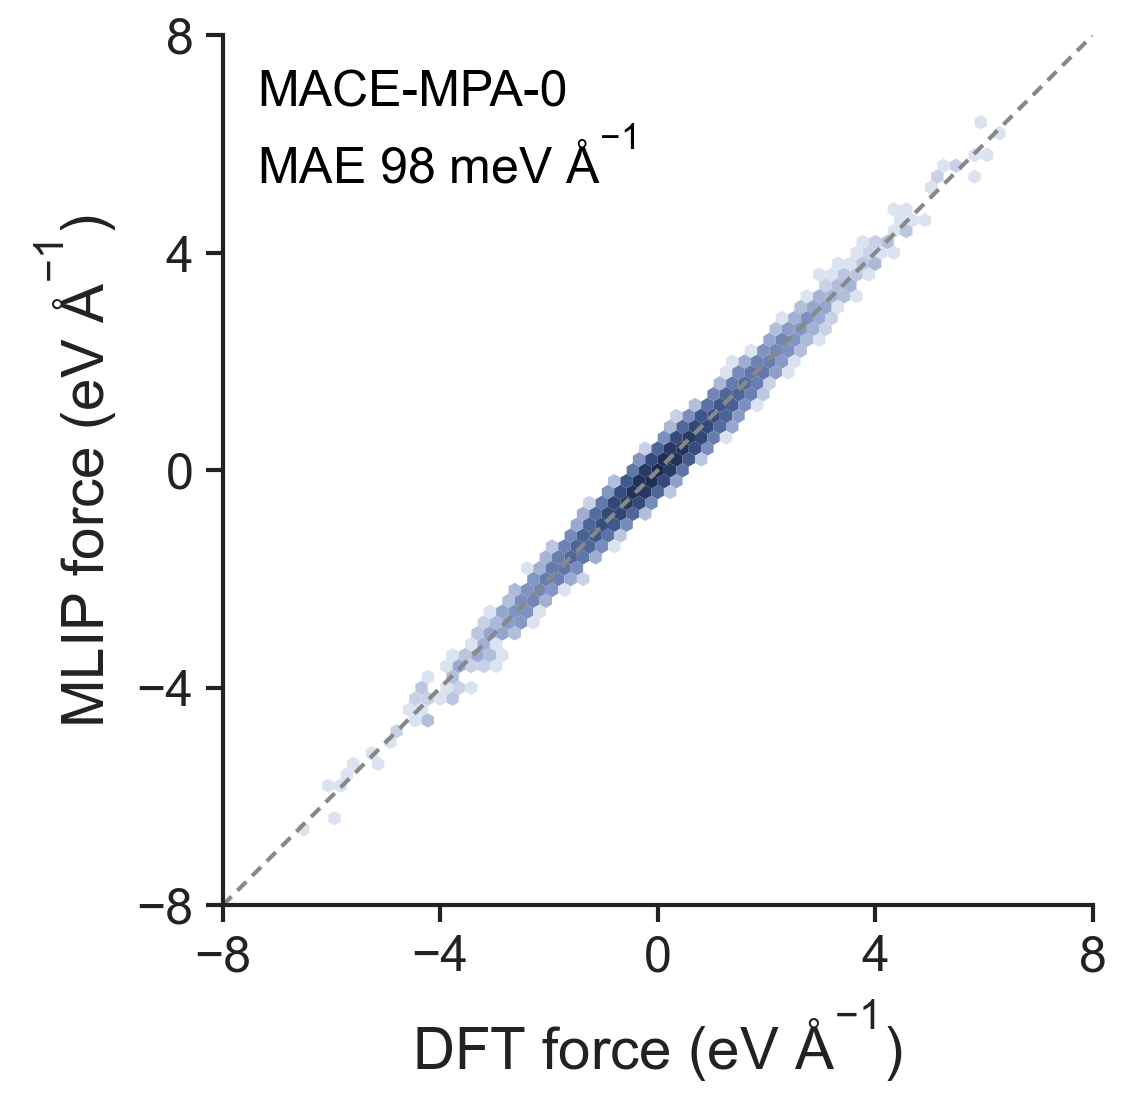

In [6]:
# ---------------- 本面板配色 ----------------
from matplotlib.colors import LinearSegmentedColormap
Ca_CMAP = LinearSegmentedColormap.from_list("pa", ["#DCE3F0", "#7C90C0", "#3C5488", "#1B2A4E"])
Ca_DIAG = "#888888"
# --------------------------------------------
def parity(fig, spec, k, cmap):
    ax = fig.add_subplot(spec)
    fm = l0_forces(k).ravel(); fr = F_REF.ravel()
    ax.hexbin(fr, fm, gridsize=70, bins="log", cmap=cmap, mincnt=1, extent=(-8, 8, -8, 8), linewidths=0)
    ax.plot([-8, 8], [-8, 8], color=Ca_DIAG, lw=0.5, ls=(0, (3, 2)))
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([-8, -4, 0, 4, 8]); ax.set_yticks([-8, -4, 0, 4, 8])
    mae = np.mean(np.abs(fm - fr))
    ax.text(0.04, 0.96, f"{lab(k)}\nMAE {mae*1000:.0f} meV Å$^{{-1}}$", transform=ax.transAxes, va="top", fontsize=FS_ANNOT)
    ax.set_xlabel("DFT force (eV Å$^{-1}$)"); ax.set_ylabel("MLIP force (eV Å$^{-1}$)")
    return ax
def draw_a(fig, spec):
    return parity(fig, spec, "mace_mpa0", Ca_CMAP)
panel_run("a", draw_a)

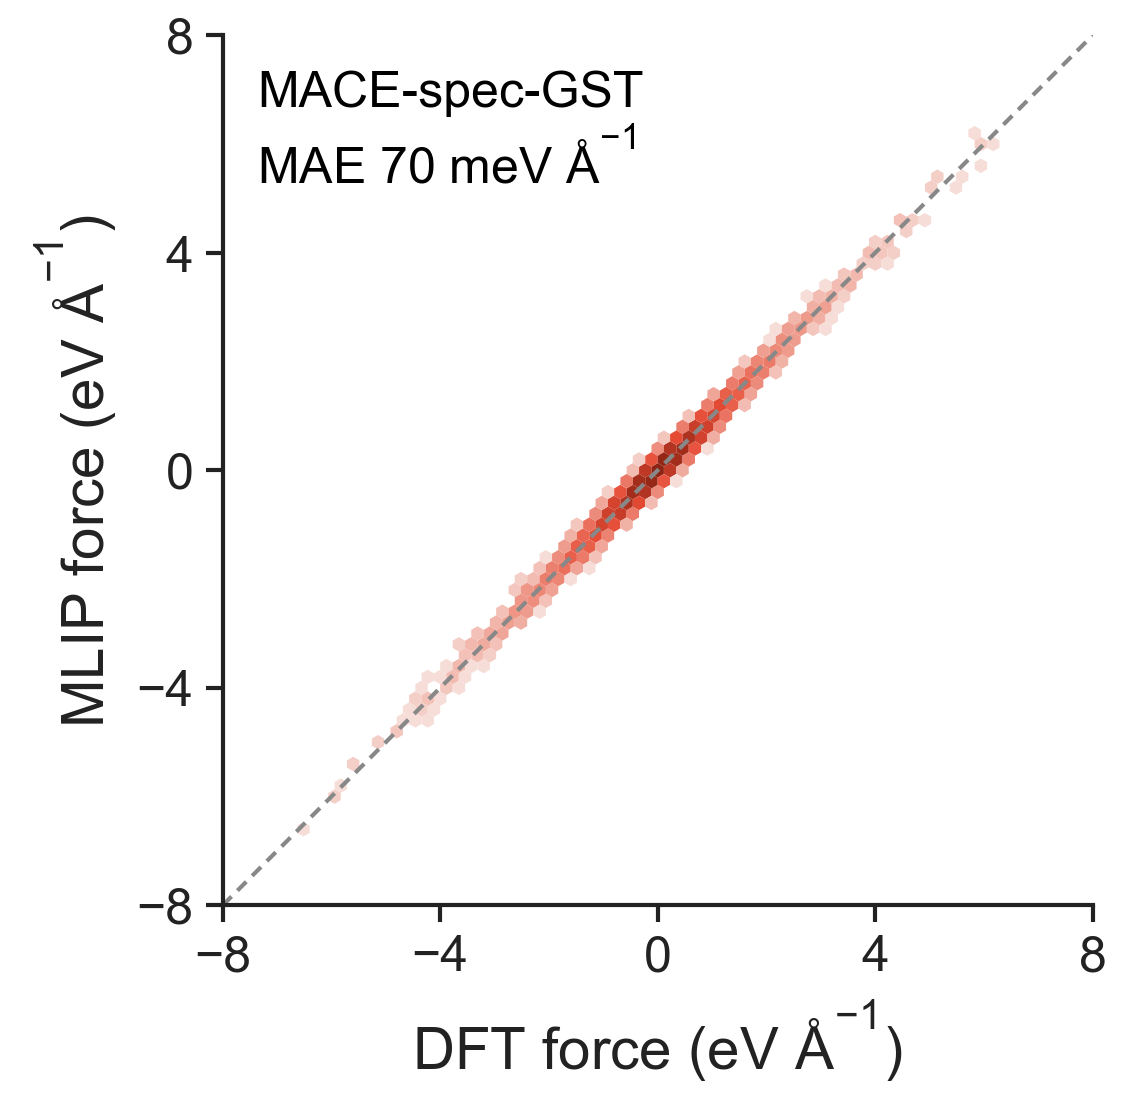

In [7]:
# ---------------- 本面板配色 ----------------
from matplotlib.colors import LinearSegmentedColormap
Cb_CMAP = LinearSegmentedColormap.from_list("pb", ["#F6DDD8", "#EE9A8B", "#E64B35", "#8E2414"])
# --------------------------------------------
def draw_b(fig, spec):
    return parity(fig, spec, "mace_spec_gst", Cb_CMAP)
panel_run("b", draw_b)

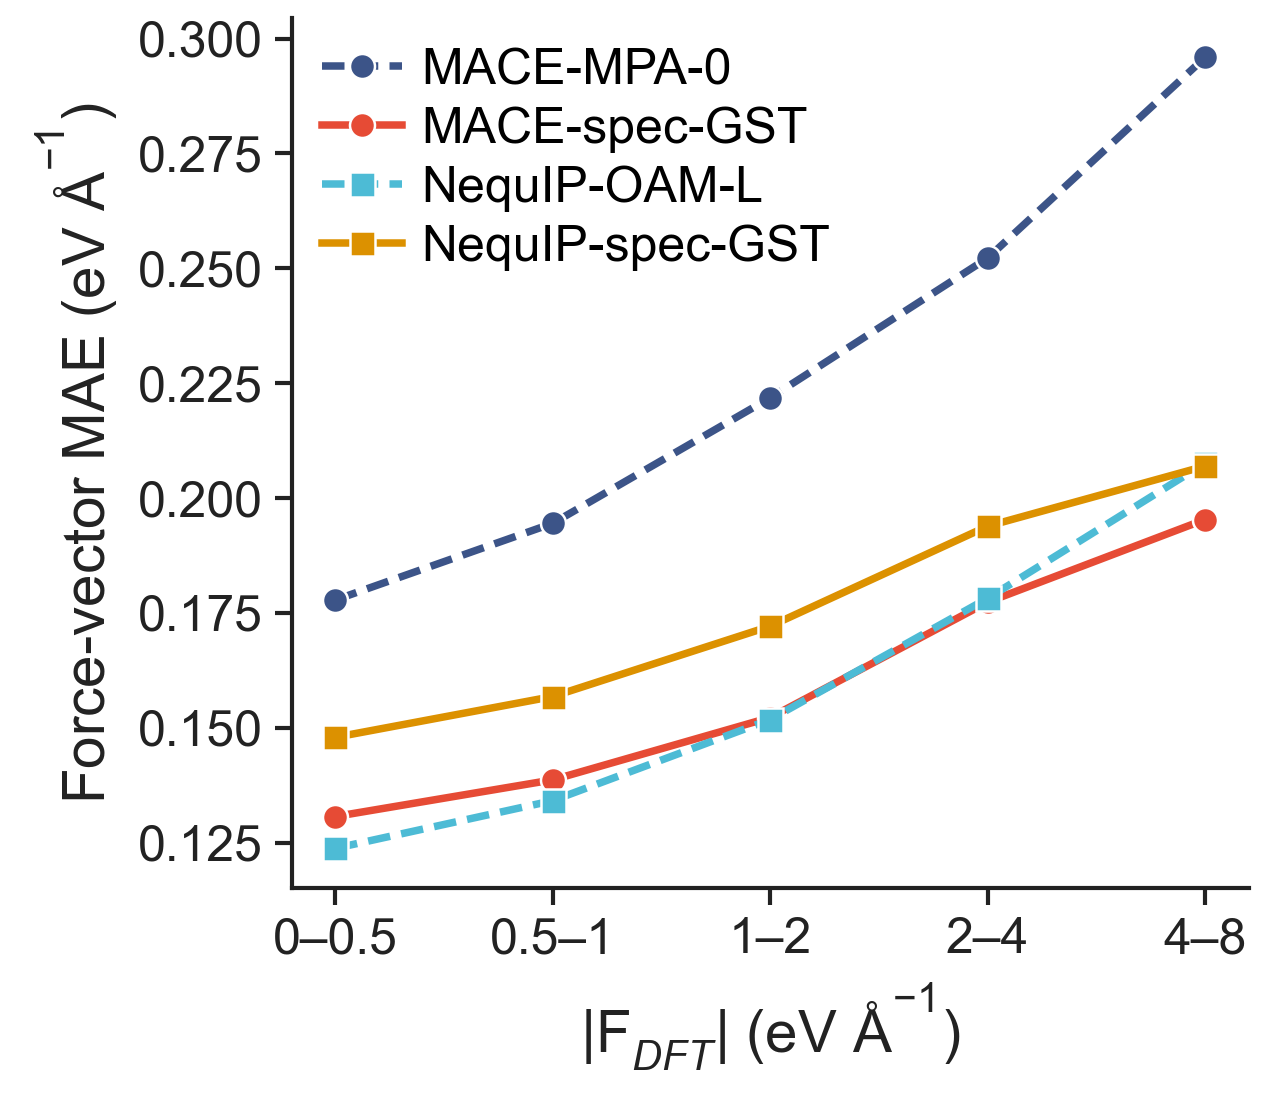

In [8]:
# ---------------- 本面板配色：沿用 style.MODELS ----------------
BINS = ["[0,0.5)", "[0.5,1)", "[1,2)", "[2,4)", "[4,8)"]
def draw_c(fig, spec):
    ax = fig.add_subplot(spec)
    x = np.arange(len(BINS))
    for k in FOCUS:
        v = [L0[k].get(f"L0.force_vector_mae.|F|={b}", {}).get("value", np.nan) for b in BINS]
        ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.plot(x, v, color=col(k), marker=mkr(k), ms=3, ls=ls, mec="white", mew=0.3, label=lab(k))
    ax.set_xticks(x); ax.set_xticklabels([b.strip("[)").replace(",", "–") for b in BINS])
    ax.set_xlabel("|F$_{DFT}$| (eV Å$^{-1}$)"); ax.set_ylabel("Force-vector MAE (eV Å$^{-1}$)")
    ax.legend(loc="upper left")
    return ax
panel_run("c", draw_c)

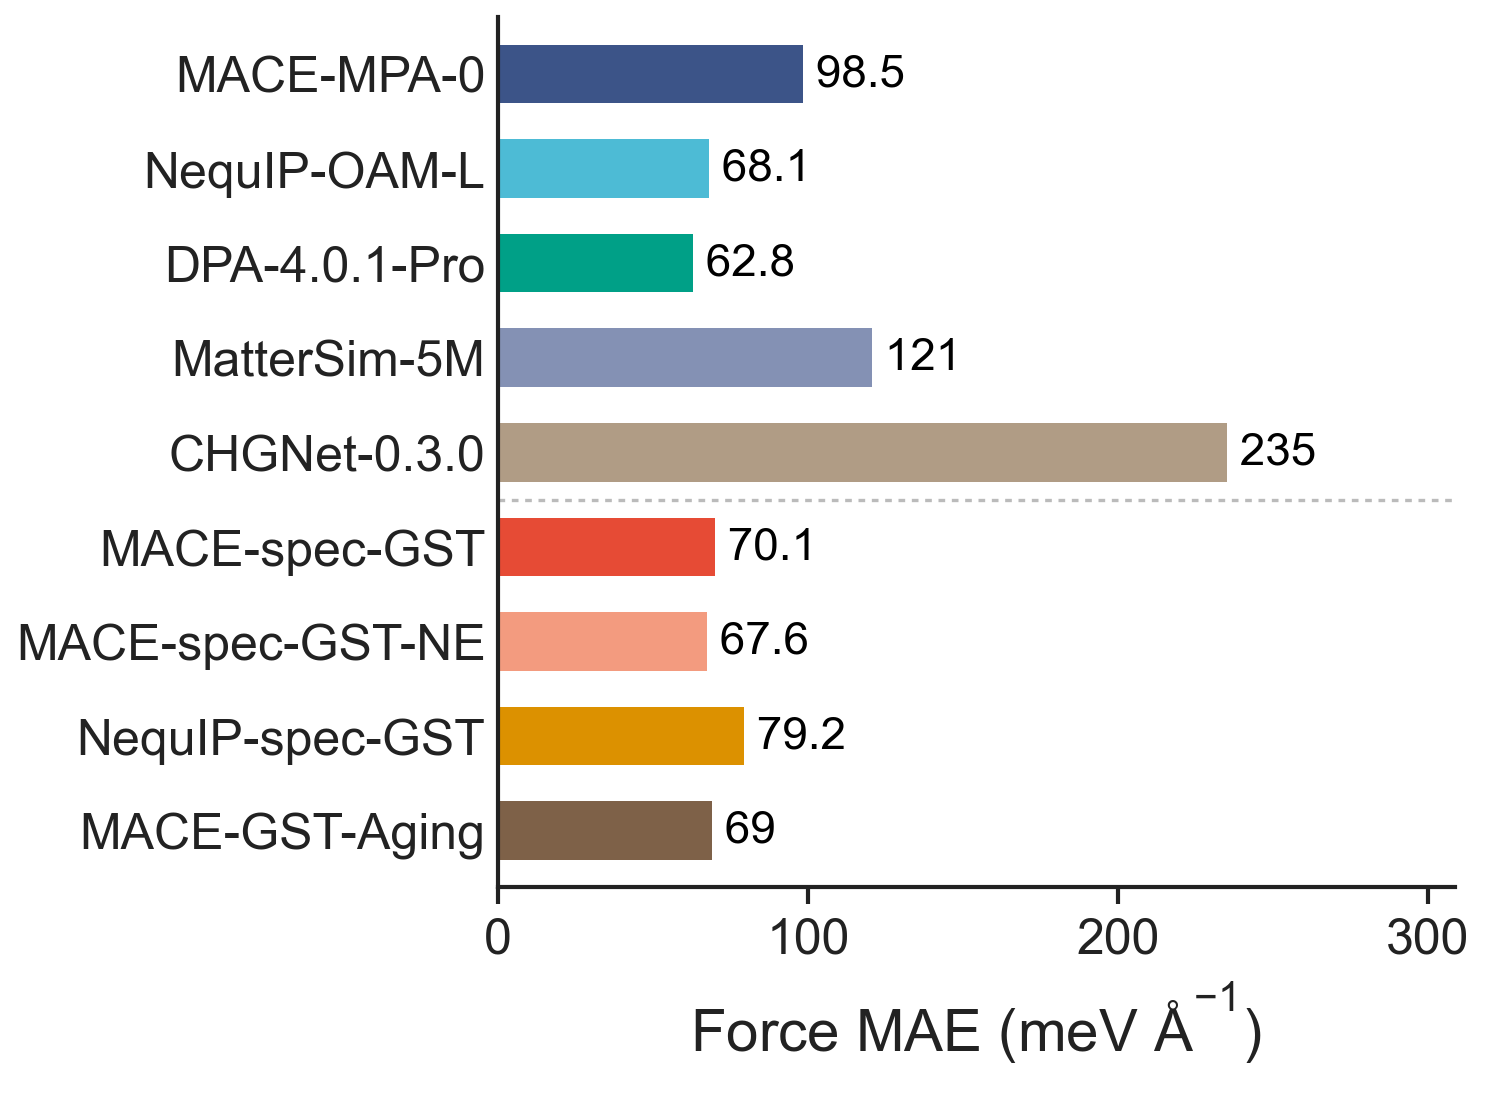

In [9]:
def hbar(fig, spec, metric, xlabel, scale=1.0, show_labels=False, log=False):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, show_labels)
    for k in SHOWCASE:
        v = L0[k].get(metric, {}).get("value", np.nan) * scale
        ax.barh(y[k], abs(v), height=0.62, color=col(k), lw=0)
        ax.text(abs(v), y[k], f" {abs(v):.3g}", va="center", fontsize=FS_ANNOT - 0.5)
    ax.set_xlabel(xlabel)
    if log: ax.set_xscale("log")
    ax.set_xlim(0, ax.get_xlim()[1] * 1.25)
    return ax
def draw_d(fig, spec):
    return hbar(fig, spec, "L0.force_mae", "Force MAE (meV Å$^{-1}$)", scale=1000, show_labels=True)
panel_run("d", draw_d)

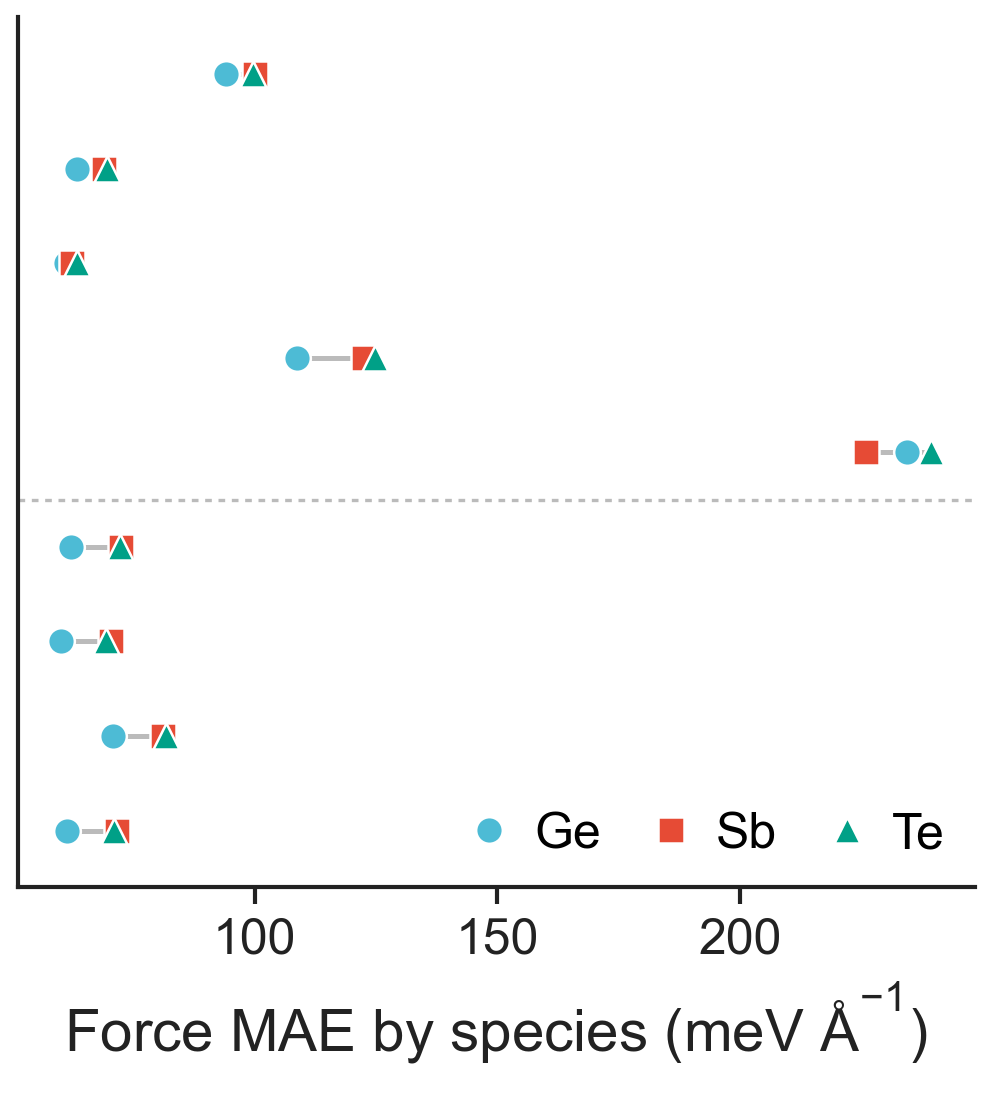

In [10]:
# ---------------- 本面板配色 ----------------
Ce_SPECIES = {"Ge": "#4DBBD5", "Sb": "#E64B35", "Te": "#00A087"}
Ce_MARK = {"Ge": "o", "Sb": "s", "Te": "^"}
Ce_LINK = "#BBBBBB"
# --------------------------------------------
def draw_e(fig, spec):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, False)
    for k in SHOWCASE:
        vals = [L0[k][f"L0.force_mae.species={s}"]["value"] * 1000 for s in Ce_SPECIES]
        ax.plot([min(vals), max(vals)], [y[k]] * 2, color=Ce_LINK, lw=0.6, zorder=1)
        for s, v in zip(Ce_SPECIES, vals):
            ax.plot(v, y[k], Ce_MARK[s], color=Ce_SPECIES[s], ms=3.2, mec="white", mew=0.3, zorder=2,
                    label=s if k == SHOWCASE[0] else None)
    ax.set_xlabel("Force MAE by species (meV Å$^{-1}$)")
    ax.legend(loc="lower right", ncol=3, handletextpad=0.1, columnspacing=0.6)
    return ax
panel_run("e", draw_e)

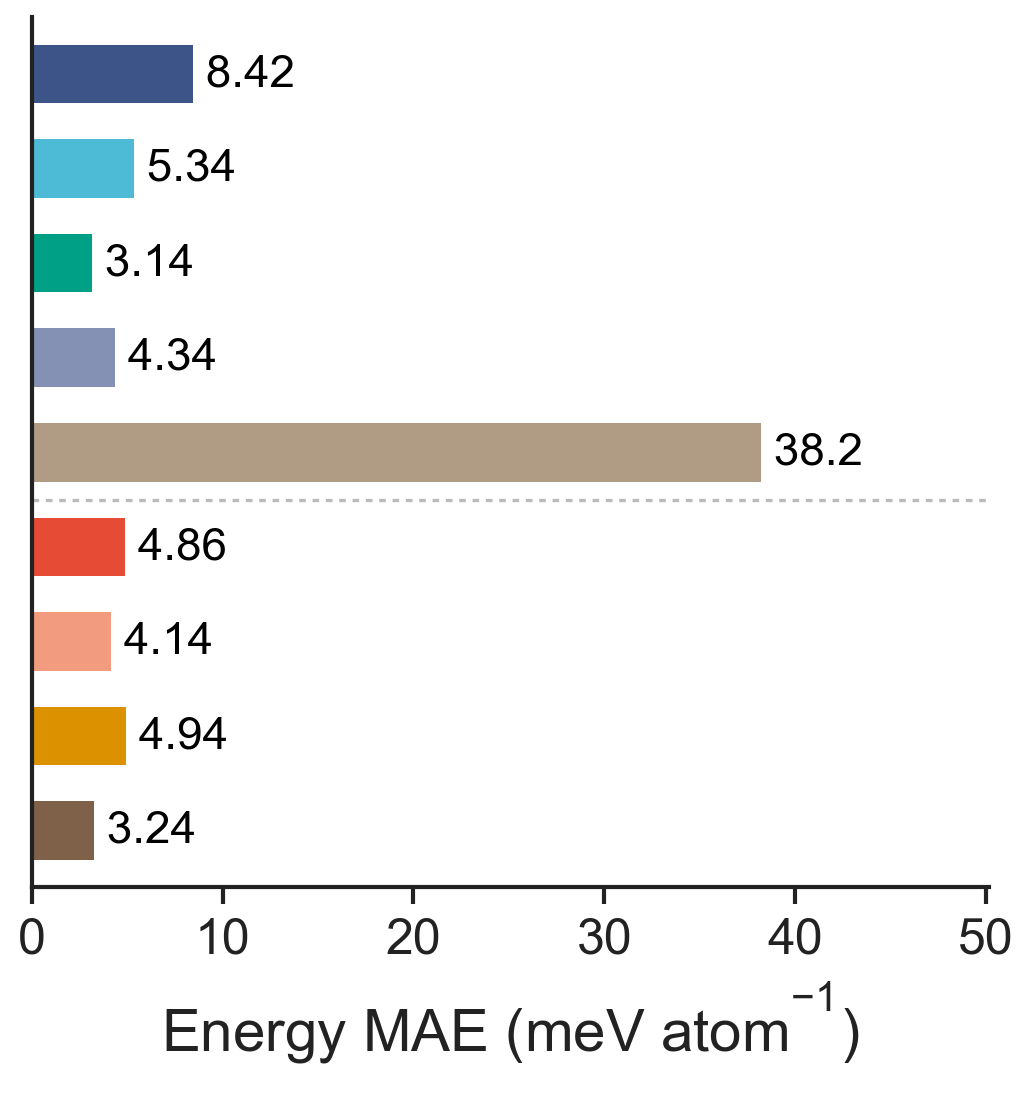

In [11]:
def draw_f(fig, spec):
    return hbar(fig, spec, "L0.energy_mae", "Energy MAE (meV atom$^{-1}$)")
panel_run("f", draw_f)

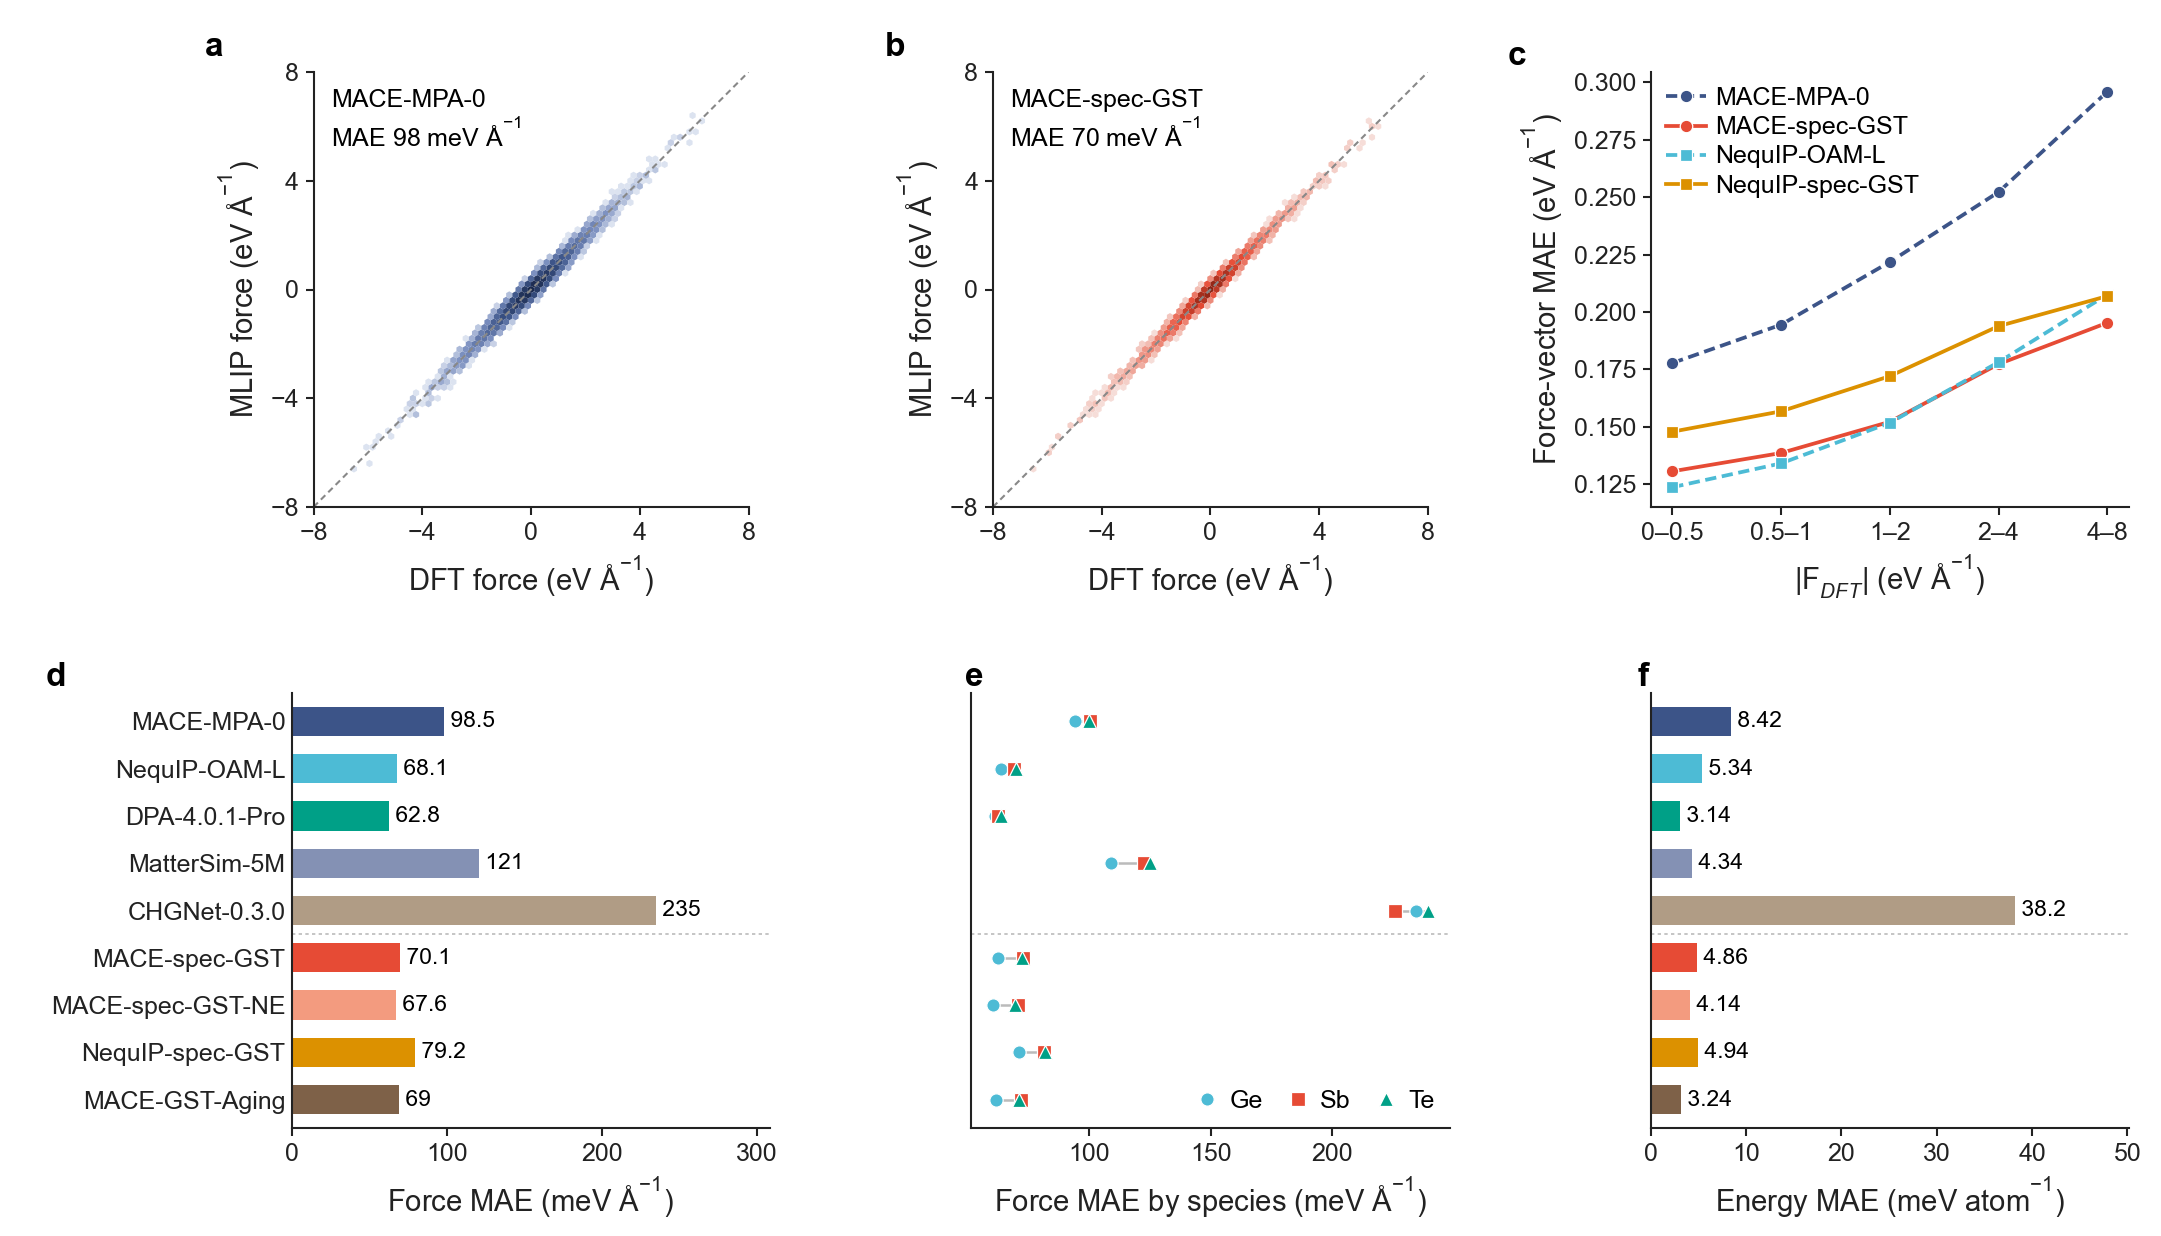

In [12]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig2_L0")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))